# Support Vector Machines: From Linear to RBF-Kernel Classification

This notebook builds up the **Support Vector Machine (SVM)** step by step:

1. **Part 1 – Linear SVM**
   - the idea of a *maximum-margin* separating hyperplane
   - the hard-margin optimisation problem
   - the soft-margin problem and the role of the parameter $C$
   - the dual problem and *support vectors*
   - a from-scratch implementation via sub-gradient descent
2. **Part 2 – Non-linear SVM with the RBF kernel**
   - why a straight line fails on some data
   - explicit feature maps $\phi(x)$
   - the *kernel trick*
   - the RBF (Gaussian) kernel and the effect of $\gamma$ and $C$
   - model selection with cross-validation

Two small datasets are used (both in `data/`, generated by `make_datasets.py`):

| File | Description |
|---|---|
| `data/linear_data.csv` | two Gaussian clouds, linearly separable |
| `data/nonlinear_data.csv` | two concentric rings, **not** linearly separable |

Each file has the columns `x1`, `x2` (features) and `label` $\in \{-1, +1\}$.

---
# Vorbereitung
## Teil 1: Dependencies

In [184]:
# Mathe / ML
# numpy: fast arrays and linear algebra (used for the maths and the decision function)
import numpy as np
# pandas: reads the CSV files into tables (DataFrames)
import pandas as pd

# scikit-learn: the Support Vector Classifier (SVC) implementation
from sklearn.svm import SVC
# train/test split, hyperparameter grid search, and stratified k-fold cross-validation
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
# accuracy metric and the confusion-matrix plotting helper
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Visualisierung
# matplotlib's pyplot interface for creating figures and axes
import matplotlib.pyplot as plt
# builds a custom colormap (used for the background shading of the decision regions)
from matplotlib.colors import LinearSegmentedColormap
# lightweight line/marker objects used to build custom legends
from matplotlib.lines import Line2D

---
## Teil 2: Visualisierung

In [185]:
# Darstellung der Plots innerhalb des Notebooks
%matplotlib inline

# Farben
COLOR_C_1 = "#0002c9"        # Klasse 1: blau
COLOR_C_2 = "#eb6834"        # Klasse 2: orange

BLACK = "#0b0b0b"
GREY = "#52514e"
LIGHT_GREY = "#e4e3df"

# Farbverlauf zur Visualisierung des Abstandes der Klassen
BG_CMAP = LinearSegmentedColormap.from_list("bg", ["#b7d3f6", "#f6f5f2", "#f8c7b2"])


# Standard fuer alle Plots: weisser hintergrund,
# kein top / right frame, Grid Darstellung, keine Legende
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GREY, "axes.labelcolor": BLACK, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": LIGHT_GREY, "grid.linewidth": 0.8,
    "xtick.color": GREY, "ytick.color": GREY, "legend.frameon": False,
})

# Darstellung der Klassen:
# - Klasse 1: Blau, Kreis
# - Klasse 2: Orange, Viereck
#
# ax: matplotlib axes Objekt
# feature_matrix: 2 Werte (Spalte) per Datenpunkt (Reihe)
# label_vector: fuer jeden Datenpunkt in der feature matrix ein Label (-1 oder 1)
# marker_size = Groesse der Datenpunkte
# alpha: Transparenz der visualisierten Datenpunkte
def scatter_classes(ax, feature_matrix, label_vector, marker_size=36, alpha=1.0):
    # Vorbereitung fuer den scatter plot:
    # Selektiere alle Datenpunkte der jeweiligen Klasse, teile sie in x1 und x2 Koordinate auf
    # und transponiere 
    class_1 = feature_matrix[label_vector == -1]
    class_1_x1 = class_1[:,0].T
    class_1_x2 = class_1[:,1].T

    class_2 = feature_matrix[label_vector == 1]
    class_2_x1 = class_2[:,0].T
    class_2_x2 = class_2[:,1].T

    # Scatter Plot fuer beide Klassen
    ax.scatter(class_1_x1, class_1_x2, c=COLOR_C_1, marker="o", s=marker_size, edgecolors="#fcfcfb", linewidths=1, alpha=alpha, label="class −1", zorder=3)
    ax.scatter(class_2_x1, class_2_x2,  c=COLOR_C_2, marker="s", s=marker_size, edgecolors="#fcfcfb", linewidths=1, alpha=alpha, label="class +1", zorder=3)
    
    # Label Bezeichnung
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")


# Plotten des Outputs der SVM, der Decision Boundary und der Support Vektoren
#
# ax: matplotlib axes Objekt
# model: sklearn.svm.SVC Objekt (handle zur SVM)
# feature_matrix: 2 Werte (Spalte) per Datenpunkt (Reihe)
# label_vector: fuer jeden Datenpunkt in der feature matrix ein Label (-1 oder 1)
# title: Titel des Plots
# show_sv: Visualisiere die Support Vektoren oder nicht
# res: pixel - Aufloesung des Plots
def plot_svm(ax, model, feature_matrix, labels, title="", show_sv=True, res=300):
    # (1) Extraktion des Wertebereiches der Features um den zu zeichnenden Bereich festzulegen
    x_min, x_max = feature_matrix[:, 0].min(), feature_matrix[:, 0].max()
    y_min, y_max = feature_matrix[:, 1].min(), feature_matrix[:, 1].max()

    # (2) Darstellung der Decision Function der SVM
    # Erstelle ein grid an X und Y Koordinaten innerhalb des Wertebereiches
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, res), np.linspace(y_min, y_max, res))

    # (2.1) Auswertung der Decision Function fuer jeden Punkt (NICHT Datenpunkt) im Grid
    #       Wir erreichen eine Farbgebung des Grids, bei der mit steigender Distanz 
    #       zur decision boundary der Hintergrund staerker Richtung Blau oder Orange gefaerbt ist.
    #       Entfernung von Extremwerten um den Farbverlauf nicht zu stoeren
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    # 95th percentile of |f| as a cap, so a few extreme values do not wash out the colour scale
    lim = np.percentile(np.abs(Z), 95)

    # (2.2) Wir verwenden die Color Map um die Konfidenz (Abstand zur Decision Boundary) der 
    # Datenpunkte zur Decision Boundary darzustellen
    ax.contourf(xx, yy, np.clip(Z, -lim, lim), levels=30, cmap=BG_CMAP, alpha=0.9, zorder=0)

    # (2.3) Darstellung der Decision Boundary und der Margins.
    #       Durchgezogene Linie fuer die Decision Boundary, gestrichelte Linie fuer die Margins
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=[GREY, BLACK, GREY],
               linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2], zorder=1)


    # (3) Darstellung der Datepunkte auf dem Grid
    scatter_classes(ax, feature_matrix, labels)

    # (4) Darstellung der Support Vektoren - wenn verfuegbar
    if show_sv and hasattr(model, "support_vectors_"):
        sv = model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1], s=150, facecolors="none", edgecolors=BLACK, linewidths=1.4, zorder=4, label="support vectors")
    
    # (5) Formatierung: Deaktivierung des default Grids, Titel und plot Dimension
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_title(title)
    ax.grid(False)

# Legende fuer die Matplotlib Plots
# include_sv: fuege Support Vektor Legende hinzu
def legend_handles(include_sv=True):
    # Legende fuer die beiden Klassen (-1 und 1), die margins und die decision boundary
    h = [Line2D([], [], marker="o", ls="", color=COLOR_C_1, label="class −1"),
         Line2D([], [], marker="s", ls="", color=COLOR_C_2, label="class +1"),
         Line2D([], [], color=BLACK, lw=2, label="decision boundary  f(x)=0"),
         Line2D([], [], color=GREY, lw=1.2, ls="--", label="margin  f(x)=±1")]
    
    # optional: Legende fuer die Support Vektoren
    if include_sv:
        h.append(Line2D([], [], marker="o", ls="", mfc="none", mec=BLACK, ms=11, label="support vectors"))
    return h

---
# Part 1 – Linear SVM classification

## 1.1 The data
We start with a two-dimensional dataset of two classes. Two dimensions keep everything visualisable;
all formulas hold unchanged in $d$ dimensions.

       x1      x2  label
0 -2.4280 -1.6827     -1
1  0.6820 -1.2526     -1
2 -0.8598 -1.8283     -1
3 -1.0391 -1.0449     -1
4 -0.6714 -0.3916     -1

class counts: {-1: 60, 1: 60}


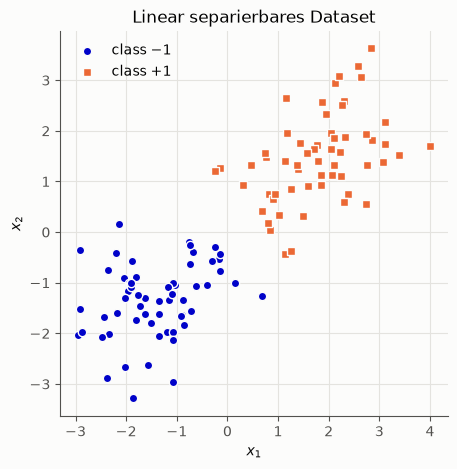

In [ ]:
# Lade die linear separierbaren Daten
lin = pd.read_csv("data/linear_data.csv")
# Feature matrix: extrahiere fuer jeden Punkt die x1 / x2 Koordinate
X_lin = lin[["x1", "x2"]].to_numpy()
# Der Labelvektor enthaelt fuer jeden Punkt eine 1 oder -1
y_lin = lin["label"].to_numpy()

# Sanity checks
print(lin.head())
print("\nclass counts:", lin["label"].value_counts().to_dict())

# Scatter plot fuer die geladenen Daten
fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_lin, y_lin)

ax.set_title("Linear separierbares Dataset")
ax.legend(loc="upper left")
ax.set_aspect("equal") # erzwinge gleiche Skalierung der Achsen
plt.show()

## 1.2 A linear classifier

A linear classifier uses a **hyperplane** (a line in 2-D) given by a weight vector $w$ and a bias $b$:

$$
f(x) = w^\top x + b, \qquad \hat y = \operatorname{sign}\big(f(x)\big).
$$

- The hyperplane is the set $\{x : w^\top x + b = 0\}$.
- $w$ is **perpendicular** to the hyperplane; $b$ shifts it away from the origin.
- The signed **distance** of a point $x_i$ from the hyperplane is $\dfrac{w^\top x_i + b}{\lVert w\rVert}$.

A point is classified correctly exactly when $y_i\,(w^\top x_i + b) > 0$.

### Which separating line is best?
If the data are separable there are **infinitely many** lines that classify all training points correctly.
The plot below shows a few of them. Intuitively, a line that passes very close to some points is fragile:
a tiny amount of noise on a new point could push it to the wrong side.

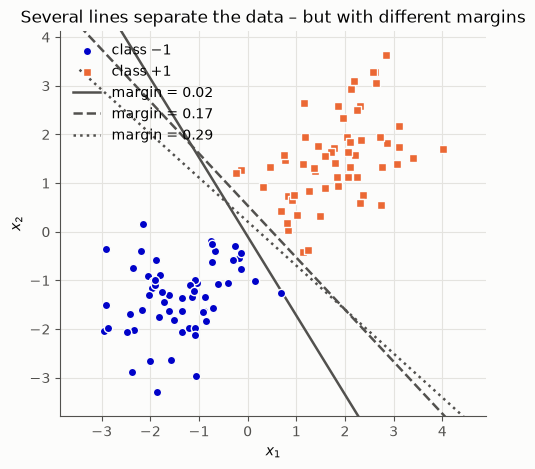

In [ ]:
# (1) Funktion zur Bestimmung des (kleinsten) Abstandes von Punkten zu einer Geraden
#     w: Normalvektor der Linie
#     b: Bias der Linie
#     X: Matrix mit allen Punkten (x1, x2 Koordinate pro Zeile)
#     y: Label Vector fuer alle Punkte in X
#
#     Return: Entfernung des naechsten Punktes zur Linie.
#             Vorzeichen: Positiv: alle Punkte liegen auf der richtigen Seite (Linie separiert die Klasse)
#                         Negativ: mindestens ein Punkt liegt auf der falschen Seite (Linie separiert die Klasse nicht)
def geometric_margin(w, b, X, y):
    # y * (X @ w + b) ist positiv fuer korrekt separierte Punkte
    # Division durch ||w|| ergibt korrekte Distanz
    return np.min(y * (X @ w + b)) / np.linalg.norm(w)

# (2) Erstellung mehrerer Linien 
# Fixierung des random seeds zur Reproduzierbarkeit
rng = np.random.default_rng(0)
# Wir wollen mehrere Linien in der Naehe des Zentrum des Koordinatensystems zeichnen
# (da dieser in der Mitte der Punktwolken liegt)
center = X_lin.mean(axis=0)
# Liste fuer alle Linien
candidates = []
# Wir samplen solange Linien, bis wir 3 separierende haben
while len(candidates) < 3:
    # Richtung der Linie
    angle = rng.uniform(0, np.pi)
    # Normaler Einheitsvektor fuer die Richtung
    w = np.array([np.cos(angle), np.sin(angle)])
    # Bias in der Naehe zum Zentrum des Koordinatensystems mit Zufallsstreuung
    b = -w @ (center + rng.normal(0, 0.4, 2))
    # Berechnung der Minimaldistanz unserer Punktwolke 
    m = geometric_margin(w, b, X_lin, y_lin)
    # wir waehlen die Linie nur aus, wenn sie die Punktwolke separiert (positives Vorzeichen)
    if m > 0.02:                       
        candidates.append((w, b, m))

# (3) Plotten der gesampelten Linien
#     Der Wertebereich bestimmt sich durch Minimal- und Maximalwerte der Punktewolke
xs = np.linspace(X_lin[:, 0].min() - 0.5, X_lin[:, 0].max() + 0.5, 2)

# (3.1) Erstellung des Scatter Plots
fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_lin, y_lin)

# Wir zeichnen jede Linie auf eine unterscheidbare Weise 
# ["-", "--", ":"] : durchgezogen, getrichtelt und gepunktet
for (w, b, m), ls in zip(candidates, ["-", "--", ":"]):
    # Zeichne die Linie fuer w0*x + w1*y + b = 0 fuer den Wertebereich
    # Erstelle einen Legendeneintrag der den Abstand des naechsten Punktes beinhaltet
    ax.plot(xs, -(w[0] * xs + b) / w[1], color=GREY, ls=ls, lw=1.8, label=f"margin = {m:.2f}")
# (3.2) Plot Formatierung
ax.set_ylim(X_lin[:, 1].min() - 0.5, X_lin[:, 1].max() + 0.5)
ax.set_title("Vergleich der separierenden Linien")
ax.legend(loc="upper right")
ax.set_aspect("equal")
plt.show()

## 1.3 The maximum-margin idea (hard-margin SVM)

The SVM picks the hyperplane with the **largest margin**, i.e. the largest distance to the closest training point.

Because $(w, b)$ and $(c\,w, c\,b)$ describe the same hyperplane for any $c>0$, we may fix the scale so that the closest points satisfy

$$
y_i\,(w^\top x_i + b) = 1 .
$$

Then the two **margin hyperplanes** $w^\top x + b = \pm 1$ pass through the closest points, and the distance between them (the full width of the "street") is

$$
\text{margin width} = \frac{2}{\lVert w\rVert}.
$$

Maximising $2/\lVert w\rVert$ is the same as minimising $\tfrac12\lVert w\rVert^2$ (which is smooth and convex), so the **hard-margin SVM** is the quadratic program

$$
\boxed{\;\min_{w,\,b}\ \tfrac12\lVert w\rVert^2
\quad\text{s.t.}\quad y_i\,(w^\top x_i + b) \ge 1,\quad i=1,\dots,n\;}
$$

The solution is **unique** and depends only on the few points lying exactly on the margin – the **support vectors**.

w = [1.584 1.553],  b = -0.135
||w|| = 2.218  ->  margin Breite 2/||w|| = 0.902
Anzahl Support Vektoren: 3
y_i * f(x_i) fuer die Support Vektoren: [1.    1.001 1.   ]


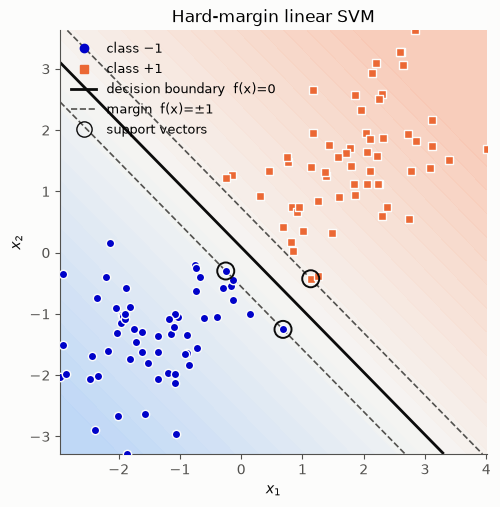

In [ ]:
# (1) Training der Lineare SVM mit sehr grossem C 
hard = SVC(kernel="linear", C=1e6).fit(X_lin, y_lin)   # grosses C entspricht ungefaehr Hard-Margin
# coef_ ist der Gewichtsvektor w, intercept_ ist der Bias b der gelernten Hyperebene
w, b = hard.coef_[0], hard.intercept_[0]

# (2) Debugging
#     Anzahl an Parameter der Hyperebene
#     Margin-Breite ist 2/||w||: der Abstand zwischen den beiden Margin-Linien
#     Anzahl der Punkte, die auf dem Margin liegen und die Loesung bestimmen
#     Pruefung der Margin-Bedingung: fuer Support Vektoren sollte y_i * f(x_i) ungefaehr 1 sein
print(f"w = {w.round(3)},  b = {b:.3f}")
print(f"||w|| = {np.linalg.norm(w):.3f}  ->  margin Breite 2/||w|| = {2/np.linalg.norm(w):.3f}")
print(f"Anzahl Support Vektoren: {len(hard.support_)}")
print("y_i * f(x_i) fuer die Support Vektoren:", (y_lin[hard.support_] * hard.decision_function(X_lin[hard.support_])).round(3))

# (3) Plot der Daten mit Decision Boundary, Margins und Support Vektoren
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_svm(ax, hard, X_lin, y_lin, "Hard-margin linear SVM")
"""
# OPTIONAL: ZEICHNE NOCH DIE PFEILE, DIE DEN ABSTAND VISUALISIEREN, EIN 
# TODO ENTSCHEIDEN OB BEHALTEN
# Margin-Breite als Pfeil von einer Margin-Linie zur anderen entlang w zeichnen
# Ersten Support Vektor als Referenzpunkt waehlen, der auf einer Margin-Linie liegt
sv0 = X_lin[hard.support_[0]]
# Einheitsvektor entlang w (senkrecht zur Hyperebene)
w_unit = w / np.linalg.norm(w)
# sv0 auf die Decision Boundary f(x)=0 projizieren (entlang w um den vorzeichenbehafteten Abstand zurueck)
p_on_plane = sv0 - hard.decision_function([sv0])[0] / np.linalg.norm(w) * w_unit
# Startpunkt des Pfeils: ein Schritt zurueck von der Boundary entlang w (Abstand 1/||w||)
a = p_on_plane - w_unit / np.linalg.norm(w)
# Endpunkt des Pfeils: ein Schritt vorwaerts entlang w (Abstand 1/||w||), der Pfeil spannt also 2/||w|| auf
c = p_on_plane + w_unit / np.linalg.norm(w)
# Doppelseitigen Pfeil von a nach c zeichnen
ax.annotate("", xy=c, xytext=a, arrowprops=dict(arrowstyle="<->", color=BLACK, lw=1.4), zorder=5)
# Formel 2/||w|| neben dem Pfeil beschriften
ax.text(*(p_on_plane + 0.25 * np.array([1, -1])), r"$\frac{2}{\|w\|}$", fontsize=15, color=BLACK, zorder=5)
# Legende mit den eigenen Eintraegen, gleiche Achsenskalierung, Anzeige
"""
ax.legend(handles=legend_handles(), loc="upper left", fontsize=9)
ax.set_aspect("equal")
plt.show()

All support vectors (ringed) satisfy $y_i f(x_i) = 1$: they sit exactly on the dashed margin lines.
Every other point could be moved (without crossing the margin) or deleted, and the solution would not change.

## 1.4 Soft margin: allowing violations

Real data are rarely perfectly separable, and even when they are, insisting on zero violations can make the
margin tiny because of one outlier. The **soft-margin SVM** introduces *slack variables* $\xi_i \ge 0$:

$$
\boxed{\;\min_{w,\,b,\,\xi}\ \tfrac12\lVert w\rVert^2 + C\sum_{i=1}^n \xi_i
\quad\text{s.t.}\quad y_i\,(w^\top x_i + b) \ge 1-\xi_i,\quad \xi_i\ge 0\;}
$$

- $\xi_i = 0$: point is on the correct side, outside the margin
- $0 < \xi_i \le 1$: point is inside the margin but still correctly classified
- $\xi_i > 1$: point is misclassified

At the optimum $\xi_i = \max\big(0,\, 1 - y_i f(x_i)\big)$, so the problem is equivalent to the
unconstrained **hinge-loss** formulation

$$
\min_{w,b}\ \underbrace{\tfrac12\lVert w\rVert^2}_{\text{wide margin}} \;+\; C\sum_{i=1}^n \underbrace{\max\big(0,\ 1 - y_i(w^\top x_i+b)\big)}_{\text{hinge loss}} .
$$

The hyper-parameter $C$ sets the trade-off:

| $C$ | Behaviour |
|---|---|
| small | violations are cheap → **wide margin**, many support vectors, more regularisation |
| large | violations are expensive → **narrow margin**, approaches the hard-margin SVM |

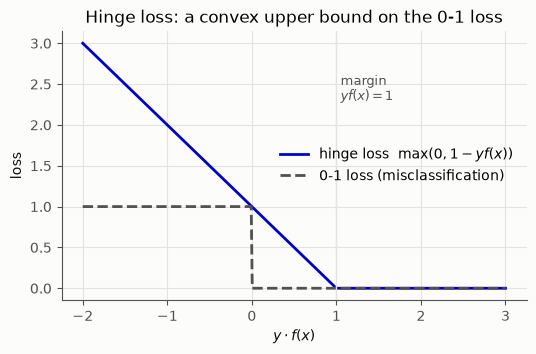

In [198]:
# (1) 400 gleichmaessig verteilte Werte des Margins y*f(x) 
#     von -2 bis 3 als x-Achse fuer die Verlustkurven
z = np.linspace(-2, 3, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))

# (2) Hinge Loss max(0, 1 - z): 
#     null jenseits des Margins (z >= 1), steigt linear darunter
ax.plot(z, np.maximum(0, 1 - z), color=COLOR_C_1, lw=2, label=r"hinge loss  $\max(0, 1 - y f(x))$")
# (3) 0-1 Loss: 1 fuer falsch klassifizierte Punkte (z <= 0), 
#     sonst 0; gestrichelt zum Vergleich
ax.plot(z, (z <= 0).astype(float), color=GREY, lw=2, ls="--", label="0-1 loss (misclassification)")
# (4) Margin
ax.axvline(1, color=LIGHT_GREY, lw=1)
ax.text(1.05, 2.3, "margin\n$y f(x) = 1$", color=GREY, fontsize=9)

# (5) Formatierung
ax.set_xlabel(r"$y \cdot f(x)$"); ax.set_ylabel("loss")
ax.set_title("Hinge loss: a convex upper bound on the 0-1 loss")
ax.legend()
plt.show()

The hinge loss is zero only when a point is **beyond** the margin ($y f(x) \ge 1$), and grows linearly otherwise.
Now let's see how $C$ changes the solution on our data:

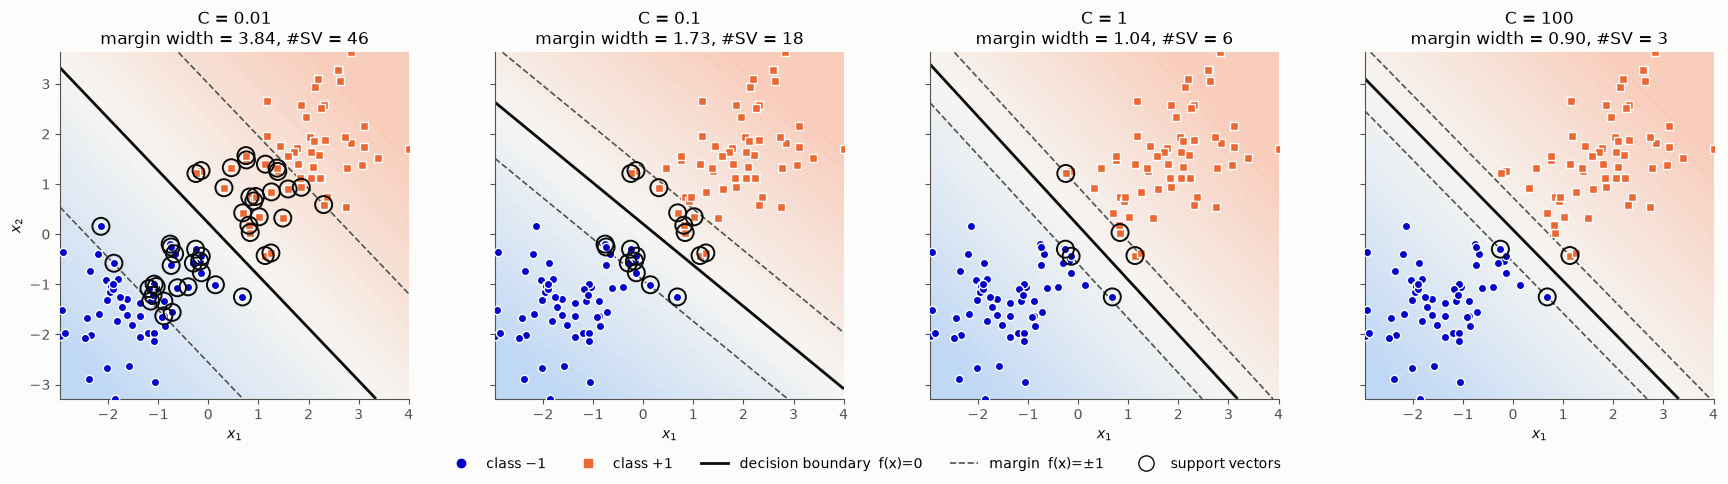

In [ ]:
# (1) Vier Werte fuer den Strafparameter C zum Vergleich 
#     (klein = breiter Margin, gross = schmaler Margin)
Cs = [0.01, 0.1, 1, 100]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)

# (2) Fuer jedes C trainieren wir eine SVM und plotteen die Ergebnisse
for ax, C in zip(axes, Cs):
    m = SVC(kernel="linear", C=C).fit(X_lin, y_lin)
    width = 2 / np.linalg.norm(m.coef_[0])
    plot_svm(ax, m, X_lin, y_lin, f"C = {C}\nmargin width = {width:.2f}, #SV = {len(m.support_)}")
    ax.set_aspect("equal")
# Eine Beschriftung (0) fuer alle plots
for ax in axes[1:]:
    ax.set_ylabel("")

# (3) Formatierung
fig.legend(handles=legend_handles(), loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.11, 1, 1])
plt.show()

With small $C$ the street is wide and many points lie inside it (all of them become support vectors).
As $C$ grows, the margin narrows until no point violates it anymore.

## 1.5 The dual problem and support vectors

Introducing Lagrange multipliers $\alpha_i \ge 0$ for the constraints gives the Lagrangian

$$
\mathcal L(w,b,\xi,\alpha,\mu) = \tfrac12\lVert w\rVert^2 + C\sum_i\xi_i
- \sum_i \alpha_i\big[y_i(w^\top x_i+b) - 1 + \xi_i\big] - \sum_i \mu_i \xi_i .
$$

Setting the derivatives w.r.t. $w$, $b$, $\xi_i$ to zero yields

$$
w = \sum_{i=1}^n \alpha_i y_i x_i, \qquad \sum_{i=1}^n \alpha_i y_i = 0, \qquad 0 \le \alpha_i \le C .
$$

Substituting back gives the **dual problem**

$$
\boxed{\;\max_{\alpha}\ \sum_{i=1}^n \alpha_i - \tfrac12 \sum_{i=1}^n\sum_{j=1}^n \alpha_i\alpha_j\, y_i y_j\, \color{#eb6834}{x_i^\top x_j}
\quad\text{s.t.}\quad 0\le\alpha_i\le C,\ \ \sum_i \alpha_i y_i = 0\;}
$$

and the decision function becomes

$$
f(x) = \sum_{i=1}^n \alpha_i y_i\, \color{#eb6834}{x_i^\top x} + b .
$$

**Key observations**

1. By the KKT complementarity conditions, $\alpha_i > 0$ **only** for points on or inside the margin –
   the **support vectors**. All other points have $\alpha_i = 0$ and do not influence the model.
2. The data appear **only through inner products** $x_i^\top x_j$ (highlighted). This is what makes the
   *kernel trick* in Part 2 possible.

Let's verify $w = \sum_i \alpha_i y_i x_i$ numerically. scikit-learn stores $\alpha_i y_i$ for the support
vectors in `dual_coef_`.

w from primal (coef_):         [1.41593 1.30162]
w from dual  (sum a_i y_i x_i): [1.41593 1.30162]
sum_i alpha_i y_i  = 0.0 (should be 0)
alphas range in [0.004, 1.000]  (bounded by C = 1)


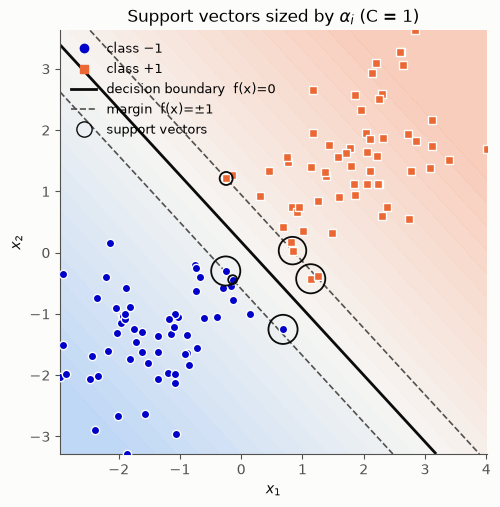

In [ ]:
# (1) Training der linearen SVM
m = SVC(kernel="linear", C=1).fit(X_lin, y_lin)


# (2) Dual Problem
# dual_coef_ enthaelt alpha_i * y_i fuer jeden Support Vektor (die dualen Variablen von scikit-learn)
alpha_y = m.dual_coef_[0]
# w aus dem dualen Problem berechnen: w = sum_i alpha_i y_i x_i (gewichtete Summe der Support Vektoren)
w_from_dual = alpha_y @ m.support_vectors_

# Vergleich von w aus dem primalen Problem (coef_) mit w aus dem dualen Problem; beide sollten gleich sein
print("w from primal (coef_):        ", m.coef_[0].round(5))
print("w from dual  (sum a_i y_i x_i):", w_from_dual.round(5))
# Nebenbedingung des dualen Problems: sum_i alpha_i y_i muss null sein
print("sum_i alpha_i y_i  =", alpha_y.sum().round(8), "(should be 0)")
# Wertebereich der absoluten alpha-Werte; keiner darf die obere Schranke C = 1 ueberschreiten
print(f"alphas range in [{np.abs(alpha_y).min():.3f}, {np.abs(alpha_y).max():.3f}]  (bounded by C = 1)")

# (3) Darstellung der Entscheidungsbereiche der SVM
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_svm(ax, m, X_lin, y_lin, r"Support vectors sized by $\alpha_i$ (C = 1)", show_sv=False)
# Jeden Support Vektor als Kreis zeichnen, dessen Groesse proportional zu |alpha_i| ist
ax.scatter(*m.support_vectors_.T, s=40 + 400 * np.abs(alpha_y) / np.abs(alpha_y).max(),
           facecolors="none", edgecolors=BLACK, linewidths=1.3, zorder=4)

# (4) Formatierung
ax.legend(handles=legend_handles(), loc="upper left", fontsize=9)
ax.set_aspect("equal")
plt.show()

Ring size is proportional to $\alpha_i$. Points strictly inside the margin hit the upper bound $\alpha_i = C$;
points exactly on the margin have $0 < \alpha_i < C$.

## 1.6 Linear SVM from scratch (sub-gradient descent)

The hinge-loss form is convex, so we can minimise it with plain (sub-)gradient descent. With
$J(w,b) = \tfrac12\lVert w\rVert^2 + C\sum_i \max(0, 1 - y_i f(x_i))$ and the set of margin violators
$\mathcal V = \{i : y_i f(x_i) < 1\}$:

$$
\nabla_w J = w - C\sum_{i\in\mathcal V} y_i x_i, \qquad
\nabla_b J = -C\sum_{i\in\mathcal V} y_i .
$$

from scratch : w = [1.416 1.302]  b = -0.228
scikit-learn : w = [1.416 1.302]  b = -0.228


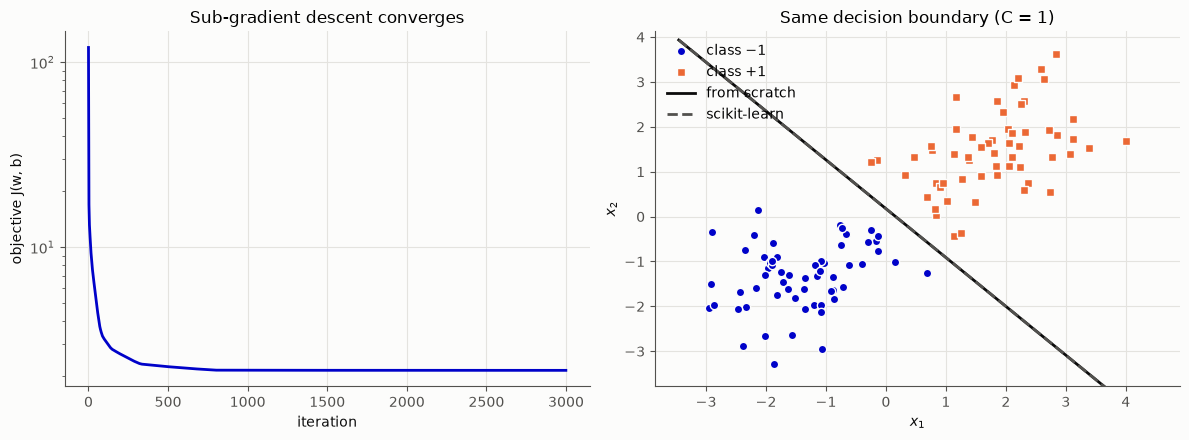

In [173]:
# Funktion: trainiert eine lineare SVM per Sub-Gradientenabstieg auf der Hinge-Loss Zielfunktion
def svm_subgradient(X, y, C=1.0, lr=1e-3, epochs=3000):
    # Start mit w = 0 und b = 0
    w, b = np.zeros(X.shape[1]), 0.0
    # Zielfunktionswert pro Iteration speichern, um die Konvergenz spaeter zu pruefen
    history = []
    # Eine Iteration des Gradientenabstiegs pro Epoche
    for t in range(epochs):
        # Vorzeichenbehafteter Margin y_i * (w.x_i + b) fuer alle Trainingspunkte
        margins = y * (X @ w + b)
        # Boolesche Maske: True fuer Punkte, die den Margin verletzen (margin < 1)
        viol = margins < 1
        # Aktuellen Zielfunktionswert 1/2 ||w||^2 + C * Summe der Hinge-Losses speichern
        history.append(0.5 * w @ w + C * np.maximum(0, 1 - margins).sum())
        # Sub-Gradient bzgl. w: w minus C mal die Summe von y_i x_i ueber die Verletzer
        grad_w = w - C * (y[viol, None] * X[viol]).sum(axis=0)
        # Sub-Gradient bzgl. b: minus C mal die Summe von y_i ueber die Verletzer
        grad_b = -C * y[viol].sum()
        step = lr / np.sqrt(1 + t / 100)            # langsam kleiner werdende Schrittweite
        # w und b einen kleinen Schritt entgegen dem Gradienten bewegen
        w, b = w - step * grad_w, b - step * grad_b
    # Finale Parameter und den Verlauf der Zielfunktion zurueckgeben
    return w, b, history

# Den selbst geschriebenen Solver auf den linearen Daten mit C = 1 ausfuehren
w_gd, b_gd, hist = svm_subgradient(X_lin, y_lin, C=1.0)
# Vergleich der eigenen Loesung mit der von scikit-learn (sollte aehnlich sein)
print("from scratch : w =", w_gd.round(3), " b =", round(b_gd, 3))
print("scikit-learn : w =", m.coef_[0].round(3), " b =", m.intercept_.round(3)[0])

# Zwei Plots: Konvergenzkurve (links) und die beiden Entscheidungsgrenzen (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
# Links: Zielfunktionswert pro Iteration in logarithmischer Skala, um Abnahme und Konvergenz zu zeigen
ax1.plot(hist, color=COLOR_C_1, lw=2)
ax1.set_xlabel("iteration"); ax1.set_ylabel("objective J(w, b)")
ax1.set_title("Sub-gradient descent converges")
ax1.set_yscale("log")

# Rechts: die Trainingspunkte mit beiden Entscheidungsgrenzen als Linien
scatter_classes(ax2, X_lin, y_lin)
# x-Koordinaten zum Zeichnen der Linien ueber die Daten
xs = np.linspace(X_lin[:, 0].min() - 0.5, X_lin[:, 0].max() + 0.5, 2)
# Grenze des selbst geschriebenen Solvers (durchgezogene Linie)
ax2.plot(xs, -(w_gd[0] * xs + b_gd) / w_gd[1], color=BLACK, lw=2, label="from scratch")
# Grenze von scikit-learn (gestrichelt), zum Vergleich
ax2.plot(xs, -(m.coef_[0][0] * xs + m.intercept_[0]) / m.coef_[0][1], color=GREY, lw=2, ls="--", label="scikit-learn")
# Vertikaler Wertebereich des Plots
ax2.set_ylim(X_lin[:, 1].min() - 0.5, X_lin[:, 1].max() + 0.5)
ax2.set_title("Same decision boundary (C = 1)")
ax2.legend(loc="upper left")
# Abstand zwischen den Plots anpassen und anzeigen
plt.tight_layout()
plt.show()

## 1.7 Evaluating on held-out data
Finally we evaluate the linear SVM on a held-out test set.

train accuracy: 1.000
test  accuracy: 1.000


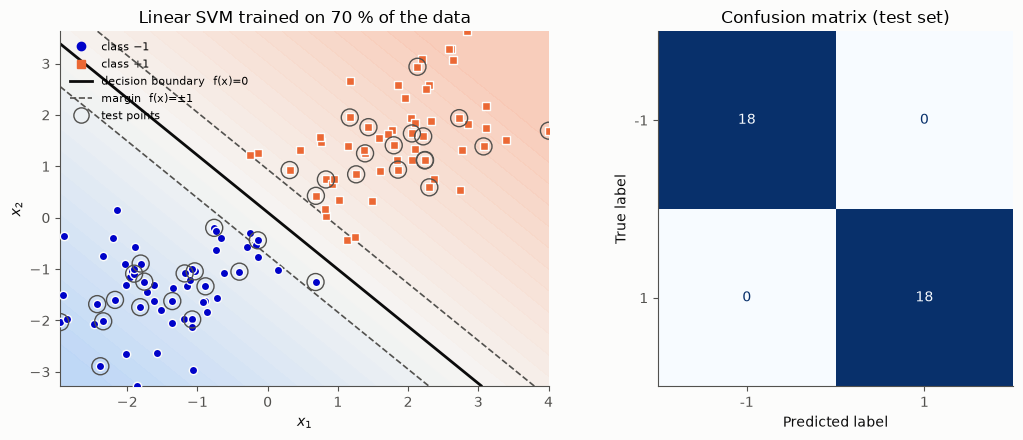

In [174]:
# Daten aufteilen: 70 % Training, 30 % Test; stratify sorgt dafuer, dass das Klassenverhaeltnis in beiden Mengen gleich bleibt
X_tr, X_te, y_tr, y_te = train_test_split(X_lin, y_lin, test_size=0.3, stratify=y_lin, random_state=0)
# Lineare SVM (C = 1) nur auf dem Trainingsteil trainieren
lin_svm = SVC(kernel="linear", C=1).fit(X_tr, y_tr)
# Genauigkeit auf den Trainingsdaten (wie gut das Modell die gesehenen Daten trifft)
print(f"train accuracy: {lin_svm.score(X_tr, y_tr):.3f}")
# Genauigkeit auf den ungesehenen Testdaten (die ehrliche Schaetzung fuer neue Daten)
print(f"test  accuracy: {lin_svm.score(X_te, y_te):.3f}")

# Zwei Plots: Entscheidungsbereiche (links) und Confusion Matrix (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
# Links: Entscheidungsbereiche des Modells auf allen Punkten zeichnen (ohne Support Vektoren)
plot_svm(ax1, lin_svm, X_lin, y_lin, "Linear SVM trained on 70 % of the data", show_sv=False)
# Testpunkte mit Kreisen markieren, damit sie zwischen den anderen erkennbar sind
ax1.scatter(*X_te.T, s=150, facecolors="none", edgecolors=GREY, linewidths=1, zorder=4)
# Legende mit den Standardeintraegen plus einem Eintrag fuer die Testpunkte
ax1.legend(handles=legend_handles(False) + [Line2D([], [], marker="o", ls="", mfc="none", mec=GREY, ms=11, label="test points")],
           loc="upper left", fontsize=8)
# Rechts: Confusion Matrix auf dem Testset (Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse)
ConfusionMatrixDisplay.from_estimator(lin_svm, X_te, y_te, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title("Confusion matrix (test set)"); ax2.grid(False)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

---
# Part 2 – Non-linear classification with RBF kernels

## 2.1 When a straight line is not enough
Our second dataset consists of two concentric rings. No straight line can separate them.

class counts: {1: 150, -1: 150}


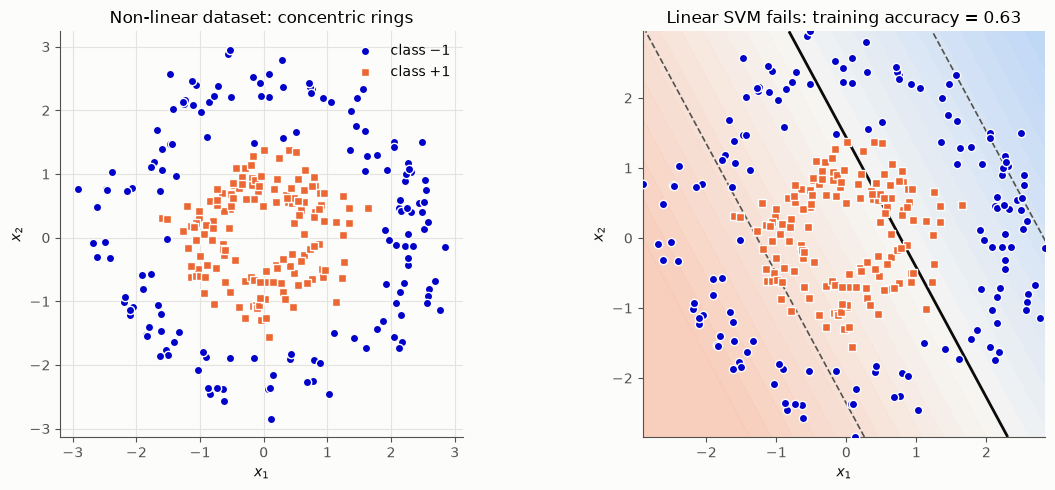

In [199]:
# (1) Laden der Daten
nl = pd.read_csv("data/nonlinear_data.csv")
X_nl = nl[["x1", "x2"]].to_numpy()
y_nl = nl["label"].to_numpy()

# (2) Debugging
print("class counts:", nl["label"].value_counts().to_dict())

# (3) Training der linearen SVM
lin_try = SVC(kernel="linear", C=1).fit(X_nl, y_nl)

# Zwei Plots: die Rohdaten (links) und die fehlschlagende lineare SVM (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
scatter_classes(ax1, X_nl, y_nl)
ax1.set_title("Non-linear dataset: concentric rings"); ax1.legend(loc="upper right"); ax1.set_aspect("equal")

# Rechts: Entscheidungsbereiche der linearen SVM; die Trainingsgenauigkeit steht im Titel
plot_svm(ax2, lin_try, X_nl, y_nl, f"Linear SVM fails: training accuracy = {lin_try.score(X_nl, y_nl):.2f}", show_sv=False)
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

The linear SVM is only slightly better than chance (50 % for two balanced classes): the classes are **not linearly separable** in $(x_1, x_2)$.

## 2.2 Idea: map the data to a higher-dimensional space

Suppose we add a third feature, the squared distance from the origin:

$$
\phi(x_1, x_2) = \big(x_1,\ x_2,\ x_1^2 + x_2^2\big).
$$

In this 3-D **feature space** the inner ring is "low" and the outer ring is "high", so a flat plane
$x_1^2 + x_2^2 = \text{const}$ separates them. A **linear** classifier in feature space corresponds to a
**non-linear** (here: circular) boundary in the original space.

linear SVM in feature space: training accuracy = 0.983


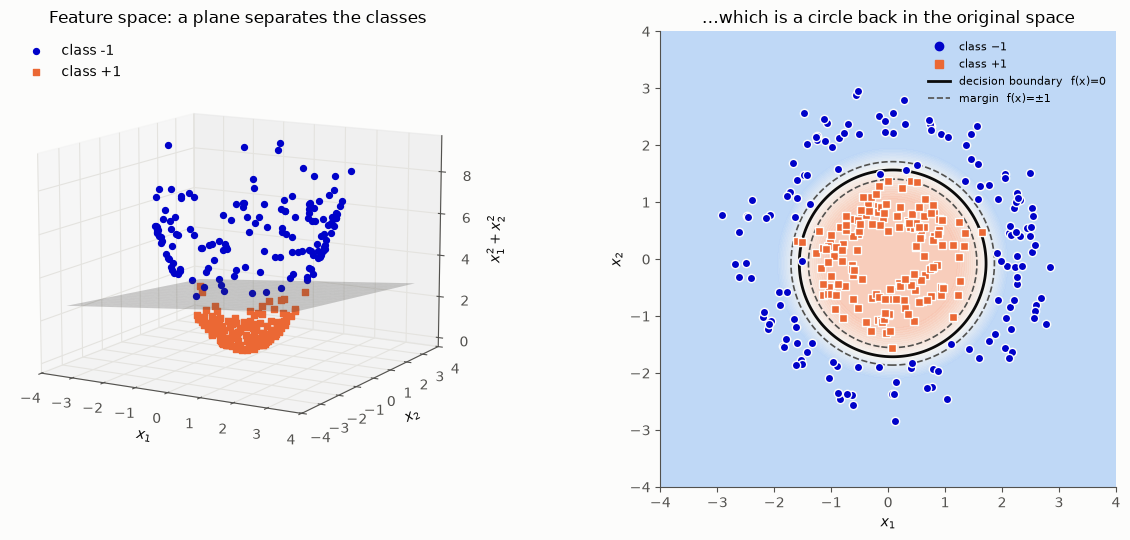

In [ ]:
# TODO: OPTIONAL - RAUSNEHMEN?
# Explizite Feature Map phi(x) = (x1, x2, x1^2 + x2^2): der quadrierte Abstand vom Ursprung wird als drittes Feature hinzugefuegt
r2 = (X_nl ** 2).sum(axis=1)
# Die Originalfeatures mit r2 zur 3-D Feature Matrix Phi zusammenfuegen
Phi = np.c_[X_nl, r2]
# Lineare SVM im 3-D Feature Raum trainieren (dort lassen sich die Ringe jetzt trennen)
lin3d = SVC(kernel="linear", C=1).fit(Phi, y_nl)
# Gewichtsvektor und Bias der trennenden Ebene im Feature Raum
w3, b3 = lin3d.coef_[0], lin3d.intercept_[0]
# Trainingsgenauigkeit im Feature Raum sollte (fast) 100 % sein
print(f"linear SVM in feature space: training accuracy = {lin3d.score(Phi, y_nl):.3f}")

# Abbildung mit einem 3-D Plot (links) und einem 2-D Plot (rechts)
fig = plt.figure(figsize=(13, 5.5))
# Links: 3-D Scatter Plot der Punkte im Feature Raum
ax = fig.add_subplot(1, 2, 1, projection="3d")
# Jede Klasse mit ihrer Farbe und ihrem Marker zeichnen
for lab, col, mk in [(-1, COLOR_C_1, "o"), (1, COLOR_C_2, "s")]:
    ax.scatter(*Phi[y_nl == lab].T, c=col, marker=mk, s=18, depthshade=False, label=f"class {lab:+d}")
# Gitter ueber x1 und x2, um die trennende Ebene zu zeichnen
gx, gy = np.meshgrid(np.linspace(-3.5, 3.5, 20), np.linspace(-3.5, 3.5, 20))
gz = -(w3[0] * gx + w3[1] * gy + b3) / w3[2]          # trennende Ebene im Feature Raum
# Die Ebene als halbtransparente Flaeche zeichnen
ax.plot_surface(gx, gy, gz, color=GREY, alpha=0.25, edgecolor="none")
# Achsenbeschriftung (die dritte Achse ist x1^2 + x2^2), Titel und Blickwinkel
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_1^2 + x_2^2$")
ax.set_title("Feature space: a plane separates the classes")
ax.view_init(elev=12, azim=-60)
ax.legend(loc="upper left")

# Rechts: die Ebene zurueck in den urspruenglichen 2-D Raum abbilden
ax2 = fig.add_subplot(1, 2, 2)
# Dichtes Gitter im urspruenglichen (x1, x2) Raum
xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
# Entscheidungsfunktion im Feature Raum an jedem Gitterpunkt auswerten, mit (x1, x2, x1^2 + x2^2) als Eingabe
Z = lin3d.decision_function(np.c_[xx.ravel(), yy.ravel(), xx.ravel() ** 2 + yy.ravel() ** 2]).reshape(xx.shape)
# Farbiger Hintergrund der Entscheidungsbereiche (Werte auf [-3, 3] begrenzt)
ax2.contourf(xx, yy, np.clip(Z, -3, 3), levels=30, cmap=BG_CMAP, alpha=0.9)
# Entscheidungsgrenze (f=0) und Margins (f=±1) im Originalraum; sie erscheinen als Kreise
ax2.contour(xx, yy, Z, levels=[-1, 0, 1], colors=[GREY, BLACK, GREY], linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
# Originale Trainingspunkte darueber zeichnen
scatter_classes(ax2, X_nl, y_nl)
ax2.set_title("…which is a circle back in the original space")
ax2.set_aspect("equal"); ax2.grid(False)
ax2.legend(handles=legend_handles(False), loc="upper right", fontsize=8)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

## 2.3 The kernel trick

Hand-crafting $\phi$ works here, but in general we don't know the right features, and useful feature spaces
can be huge (even infinite-dimensional). Recall from Section 1.5 that the dual problem and the decision function
use the data **only through inner products**. After mapping with $\phi$ they read

$$
\max_\alpha\ \sum_i \alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\,\phi(x_i)^\top\phi(x_j),
\qquad
f(x) = \sum_i \alpha_i y_i\,\phi(x_i)^\top \phi(x) + b .
$$

So we never need $\phi(x)$ itself – only a **kernel function** that computes the inner product directly:

$$
\boxed{\;K(x, z) = \phi(x)^\top \phi(z)\;}
$$

Replacing every $x_i^\top x_j$ by $K(x_i, x_j)$ is the **kernel trick**. Any function $K$ that is
symmetric and positive semi-definite (Mercer's condition) corresponds to *some* feature map $\phi$.

Common kernels:

| Kernel | $K(x,z)$ |
|---|---|
| linear | $x^\top z$ |
| polynomial | $(\gamma\, x^\top z + r)^p$ |
| **RBF / Gaussian** | $\exp\!\big(-\gamma\,\lVert x - z\rVert^2\big)$ |

## 2.4 The RBF (Gaussian) kernel

$$
K_{\text{RBF}}(x, z) = \exp\!\big(-\gamma\,\lVert x - z\rVert^2\big), \qquad \gamma > 0 \quad (\text{often } \gamma = \tfrac{1}{2\sigma^2}).
$$

- It is a **similarity measure**: $K = 1$ for identical points and decays to $0$ with distance.
- $\gamma$ controls the **reach** of each training point: large $\gamma$ → narrow bumps (very local influence);
  small $\gamma$ → wide bumps (smooth, almost linear boundaries).
- Its feature space is **infinite-dimensional**: expanding $e^{2\gamma x^\top z}$ as a Taylor series yields
  polynomial features of every degree.

The decision function becomes a weighted sum of Gaussian "bumps" centred on the support vectors:

$$
f(x) = \sum_{i \in \text{SV}} \alpha_i y_i \exp\!\big(-\gamma\lVert x_i - x\rVert^2\big) + b .
$$

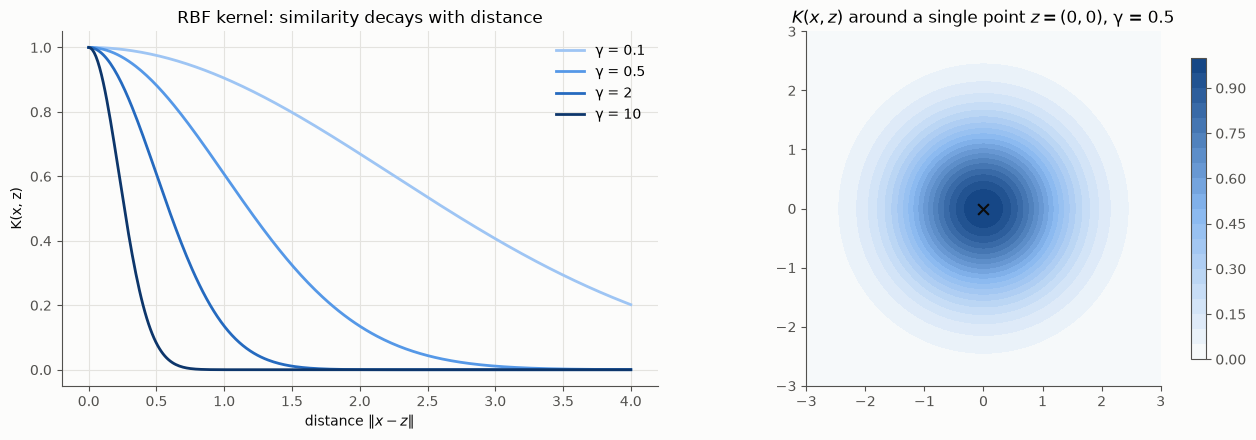

In [ ]:
# TODO - OPTIONAL - RAUSNEHMEN?
# Abstaende von 0 bis 4 fuer den Kernel-Plot (300 Punkte)
d = np.linspace(0, 4, 300)
# Mehrere Werte fuer gamma (Kernelbreite) zum Vergleich
gammas = [0.1, 0.5, 2, 10]
# Eine Farbe pro gamma: hell -> dunkel = kleines -> grosses gamma
shades = ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]   # ein Farbton, hell -> dunkel = kleines -> grosses gamma

# Zwei Plots: Kernelkurven gegen den Abstand (links) und ein 2-D Kernel-Buckel (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
# Links: K = exp(-gamma * d^2) fuer jedes gamma zeichnen; grosses gamma faellt schneller gegen null
for g, c in zip(gammas, shades):
    ax1.plot(d, np.exp(-g * d ** 2), color=c, lw=2, label=f"γ = {g}")
ax1.set_xlabel(r"distance $\|x - z\|$"); ax1.set_ylabel("K(x, z)")
ax1.set_title("RBF kernel: similarity decays with distance")
ax1.legend()

# Kernel-"Buckel" eines einzelnen Punktes in 2-D fuer ein gamma
# Gitter aus 2-D Punkten um den Ursprung
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
# RBF-Kernelwerte mit gamma = 0.5 zwischen jedem Gitterpunkt und dem Zentrum z = (0, 0)
K = np.exp(-0.5 * (xx ** 2 + yy ** 2))
# Gefuellter Konturplot der Kernelwerte mit eigener Colormap (hell -> dunkelblau)
im = ax2.contourf(xx, yy, K, levels=20, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#104281"]))
# Das Zentrum z = (0, 0) mit einem Kreuz markieren
ax2.scatter([0], [0], c=BLACK, marker="x", s=60)
ax2.set_title(r"$K(x, z)$ around a single point $z = (0,0)$, γ = 0.5")
ax2.set_aspect("equal"); ax2.grid(False)
# Farbskala der Kernelwerte anzeigen
fig.colorbar(im, ax=ax2, shrink=0.85)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

## 2.5 Training an RBF-kernel SVM

train accuracy: 0.981
test  accuracy: 0.978
support vectors: 37 of 210 training points


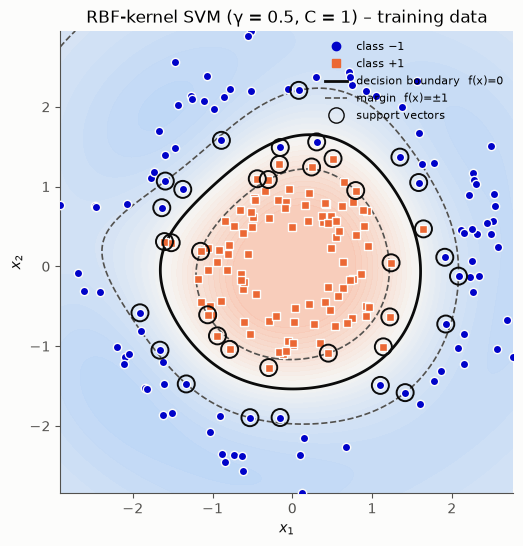

In [ ]:
# (1) Train / Testset Generierung
#     stratify: splitte gleichmaessig ueber alle Klassen, nicht nur ueber alle Daten
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X_nl, y_nl, test_size=0.3, stratify=y_nl, random_state=0)

# (2) RBF-SVM mit gamma = 0.5 (Kernelbreite) und 
#                 C = 1 (Strafparameter fuer Margin-Verletzungen) trainieren
rbf = SVC(kernel="rbf", gamma=0.5, C=1).fit(Xn_tr, yn_tr)

# (3) Debugging
print(f"train accuracy: {rbf.score(Xn_tr, yn_tr):.3f}")
print(f"test  accuracy: {rbf.score(Xn_te, yn_te):.3f}")
print(f"support vectors: {len(rbf.support_)} of {len(yn_tr)} training points")

# (4) Plot
fig, ax = plt.subplots(figsize=(6.5, 6))
plot_svm(ax, rbf, Xn_tr, yn_tr, "RBF-kernel SVM (γ = 0.5, C = 1) – training data")
ax.legend(handles=legend_handles(), loc="upper right", fontsize=8)
ax.set_aspect("equal")
plt.show()

The boundary is now a closed curve around the inner ring. Only the points near the boundary are support vectors.

### Verifying the formula
We can recompute $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$ by hand from the fitted support vectors, and
visualise how the individual Gaussian bumps add up.

max |manual - sklearn| = 2.220446049250313e-15


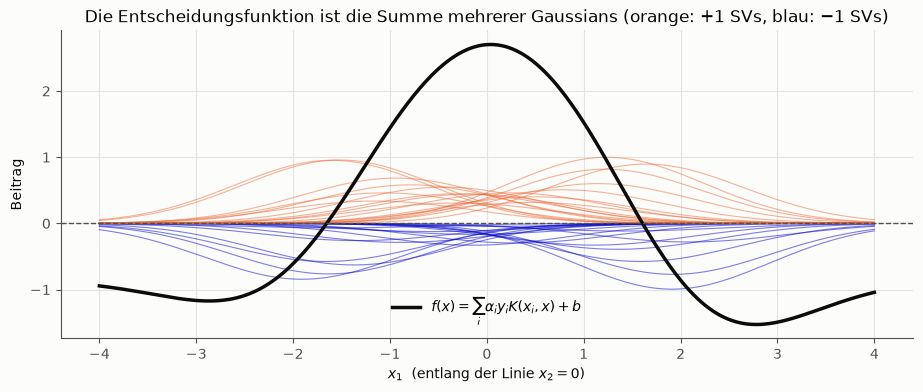

In [203]:
# OPTIONAL - RAUSNEHMEN?
# (1) Funktion: RBF-Kernelmatrix 
# K[i, j] = exp(-gamma * ||A_i - B_j||^2) 
# fuer alle Paare von Zeilen aus A und B
def rbf_kernel(A, B, gamma):
    # Quadrierte euklidische Abstaende ueber ||a||^2 + ||b||^2 - 2 a.b 
    sq = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    # Quadrierte Abstaende in Aehnlichkeiten zwischen 0 und 1 
    return np.exp(-gamma * sq)

# (2) Kernelwerte zwischen jedem Support Vektor und jedem Testpunkt berechnen
#     (Form: n_SV x n_test)
K_te = rbf_kernel(rbf.support_vectors_, Xn_te, gamma=0.5)      # (n_SV, n_test)

# (3) Entscheidungsfunktion: sum_i alpha_i y_i K(x_i, x) + b
f_manual = rbf.dual_coef_[0] @ K_te + rbf.intercept_[0]

# (4) Debugging: Pruefen, rbf_kernel() == decision_function von scikit-learn
print("max |manual - sklearn| =", np.abs(f_manual - rbf.decision_function(Xn_te)).max())

# (5) Plot der Entscheidungsfunktion
# 400 Punkte auf der Linie x2 = 0, x1 von -4 bis 4
line = np.c_[np.linspace(-4, 4, 400), np.zeros(400)]

# (5.1) Beitrag und Graph jedes Support Vektors entlang der Linie
contrib = rbf.dual_coef_[0][:, None] * rbf_kernel(rbf.support_vectors_, line, 0.5)
fig, ax = plt.subplots(figsize=(11, 4))
for c, a in zip(contrib, rbf.dual_coef_[0]):
    ax.plot(line[:, 0], c, color=COLOR_C_2 if a > 0 else COLOR_C_1, lw=0.8, alpha=0.5)

# (5.2) Summe aller SV Beitraege zeichnen
ax.plot(line[:, 0], contrib.sum(0) + rbf.intercept_[0], color=BLACK, lw=2.5, label=r"$f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$")

# (5.3) Nullinie: dort wechselt f(x) das Vorzeichen (die Entscheidungsgrenze)
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.set_xlabel("$x_1$  (entlang der Linie $x_2 = 0$)"); ax.set_ylabel("Beitrag")
ax.set_title("Die Entscheidungsfunktion ist die Summe mehrerer Gaussians (orange: +1 SVs, blau: −1 SVs)")
ax.legend(loc="lower center")
plt.show()

Along the line $x_2 = 0$ the sum $f(x)$ is positive in the middle (inner ring, class $+1$) and negative
further out (outer ring, class $-1$). It crosses $0$ at the decision boundary.

## 2.6 The effect of $\gamma$ and $C$

The RBF-SVM has two hyper-parameters:

- $\gamma$ – kernel width (how far each point's influence reaches)
- $C$ – penalty for margin violations (as in the linear case)

Both control the **bias–variance trade-off**:

| | small value | large value |
|---|---|---|
| $\gamma$ | smooth, nearly linear boundary → **underfitting** | wiggly islands around single points → **overfitting** |
| $C$ | wide soft margin, more regularisation | fits the training data tightly |

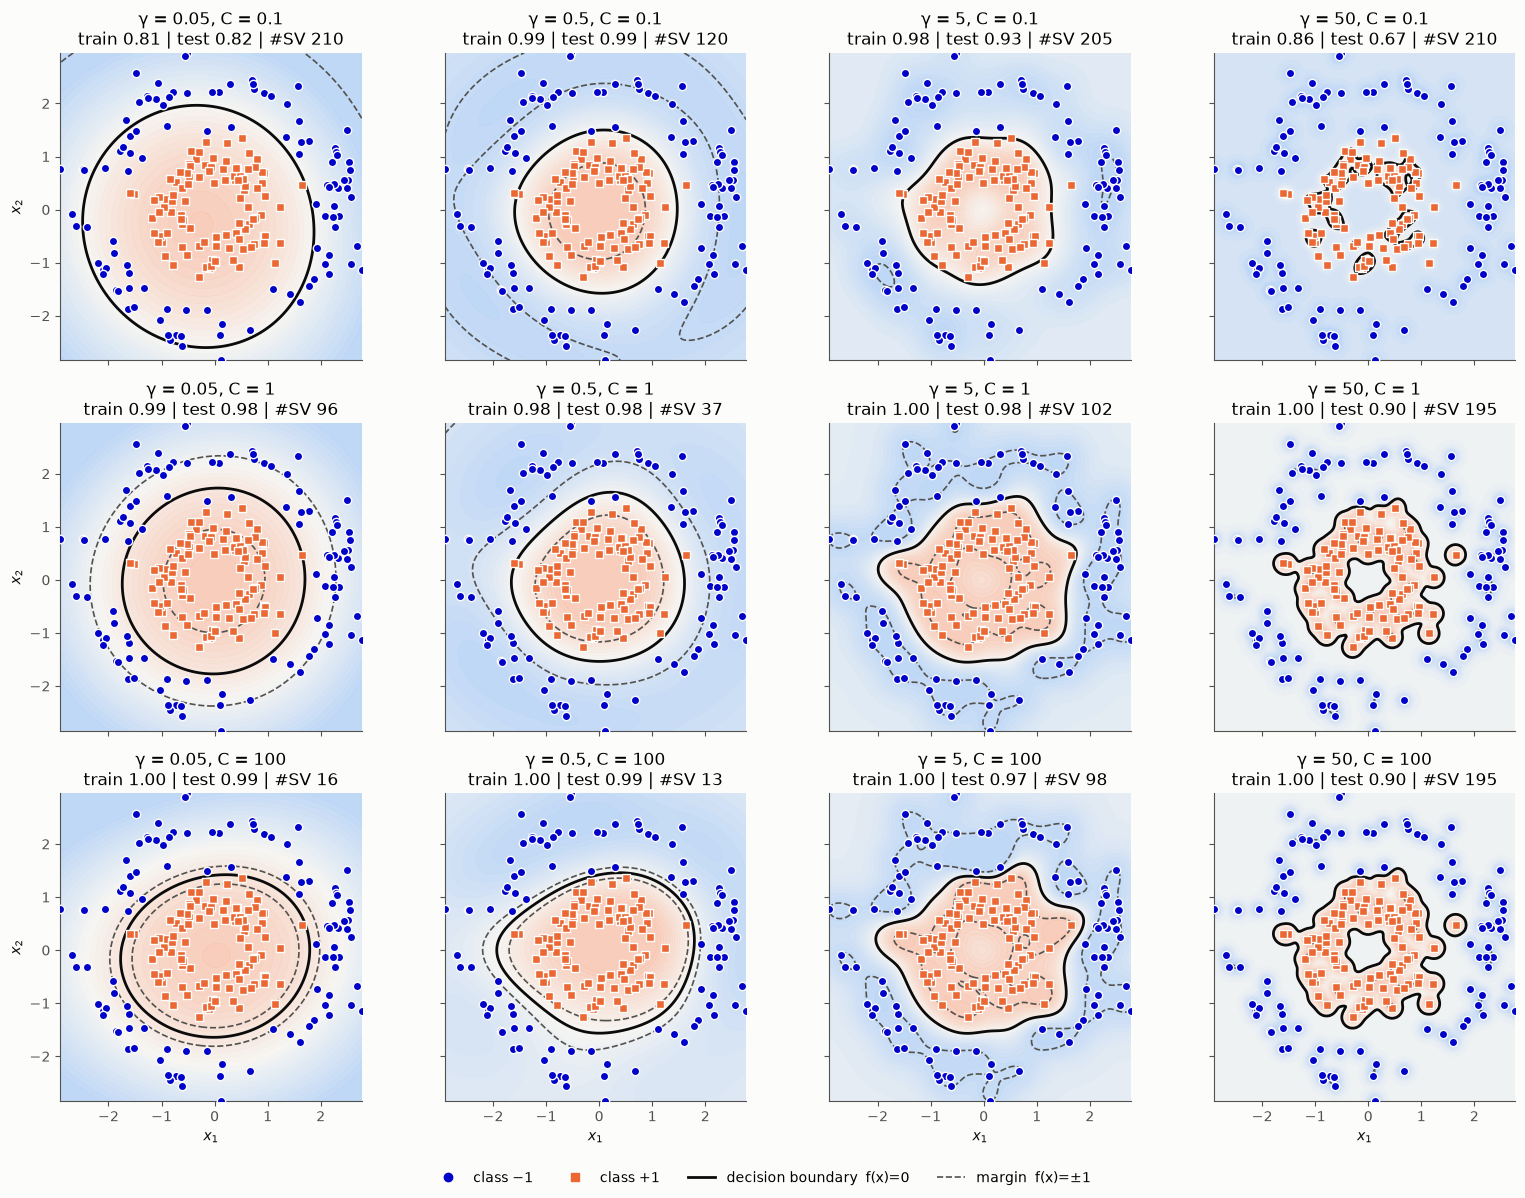

In [ ]:
# (1) Parameter fuer 
#     gamma (Spalten des Gitters) und 
#     C     (Zeilen des Gitters) 
#     zum Vergleich
gammas = [0.05, 0.5, 5, 50]
Cs = [0.1, 1, 100]

# (2) Plots fuer C (pro Zeile) und gamma (pro Spalte)
#     Fuer jede Kombination trainieren wir eine SVM!
fig, axes = plt.subplots(len(Cs), len(gammas), figsize=(16, 12), sharex=True, sharey=True)
for i, C in enumerate(Cs):
    for j, gamma in enumerate(gammas):
        # RBF-SVM mit diesem gamma und C auf den Trainingsdaten trainieren
        mdl = SVC(kernel="rbf", gamma=gamma, C=C).fit(Xn_tr, yn_tr)

        plot_svm(axes[i, j], mdl, Xn_tr, yn_tr, show_sv=False, res=200,
                 title=f"γ = {gamma}, C = {C}\ntrain {mdl.score(Xn_tr, yn_tr):.2f} | test {mdl.score(Xn_te, yn_te):.2f} | #SV {len(mdl.support_)}")
        axes[i, j].set_aspect("equal")

        # y-Beschriftung nur in der ersten Spalte und 
        # x-Beschriftung nur in der untersten Zeile behalten
        if j: axes[i, j].set_ylabel("")
        if i < len(Cs) - 1: axes[i, j].set_xlabel("")

# (3) Formatierung
fig.legend(handles=legend_handles(False), loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

- **Left column (γ = 0.05):** the bumps are very wide, so the boundary is a smooth ellipse. Combined with a small
  $C$ (top-left) the model is too stiff and **underfits**: it misplaces the boundary and every point becomes a support vector.
- **Middle columns:** a smooth closed curve that follows the gap between the rings – good train *and* test accuracy.
- **Right column (γ = 50):** each point only influences its immediate neighbourhood; the boundary breaks into
  ragged islands (note the hole in the middle and the small isolated blobs). Training accuracy is perfect but test
  accuracy drops – classic **overfitting**. Almost all points become support vectors.
- Larger $C$ makes the model fit the training data more tightly, which pushes in the same direction.

## 2.7 Choosing $\gamma$ and $C$ with cross-validation

The standard way to select hyper-parameters is a **grid search with k-fold cross-validation** on the training
set only; the test set is used once at the end. (Tip: on real data, standardise the features first – e.g. with a
`StandardScaler` in a `Pipeline` – because the RBF kernel depends on Euclidean distances. Our two features are
already on the same scale.)

best parameters: {'C': 100.0, 'gamma': 0.316}
best CV accuracy: 1.000
test accuracy   : 0.978


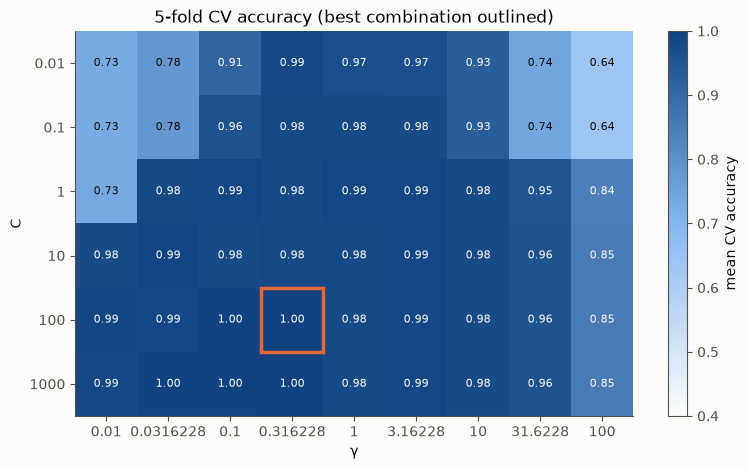

In [ ]:
# TODO OPTIONAL WUERDE ICH RAUSNEHMEN AB HIER
# Hyperparameter-Raster: 6 Werte fuer C und 9 Werte fuer gamma, beide logarithmisch verteilt (10^-2 ... 10^3 bzw. 10^-2 ... 10^2)
param_grid = {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-2, 2, 9)}
# Grid Search: probiert jedes (C, gamma) Paar mit 5-facher stratifizierter Kreuzvalidierung, nur auf den Trainingsdaten
search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0))
# Suche ausfuehren (trainiert 6 x 9 x 5 Modelle)
search.fit(Xn_tr, yn_tr)
# Beste Hyperparameter-Kombination aus der Kreuzvalidierung
print("best parameters:", {k: round(float(v), 3) for k, v in search.best_params_.items()})
# Mittlere Kreuzvalidierungs-Genauigkeit der besten Kombination
print(f"best CV accuracy: {search.best_score_:.3f}")
# Genauigkeit des besten Modells auf dem unberuehrten Testset (nur einmal, am Ende, verwendet)
print(f"test accuracy   : {search.score(Xn_te, yn_te):.3f}")

# Die flache Liste der mittleren CV-Werte in eine (C x gamma) Tabelle fuer die Heatmap umformen
scores = search.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
# Heatmap-Abbildung
fig, ax = plt.subplots(figsize=(9, 5))
# Die Werte als Farben zeichnen; die festen vmin/vmax halten die Farbskala vergleichbar
im = ax.imshow(scores, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#86b6ef", "#104281"]),
               vmin=0.4, vmax=1, aspect="auto")
# Spalten mit gamma-Werten und Zeilen mit C-Werten beschriften
ax.set_xticks(range(len(param_grid["gamma"])), [f"{g:g}" for g in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), [f"{c:g}" for c in param_grid["C"]])
ax.set_xlabel("γ"); ax.set_ylabel("C"); ax.grid(False)
# Den Wert in jede Zelle schreiben; bei dunklen Zellen weisser Text fuer bessere Lesbarkeit
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="#fcfcfb" if scores[i, j] > 0.8 else BLACK)
# Zeilen- und Spaltenindex der besten (C, gamma) Kombination bestimmen
bi = list(param_grid["C"]).index(search.best_params_["C"])
bj = list(param_grid["gamma"]).index(search.best_params_["gamma"])
# Beste Zelle mit einem orangen Rechteck umranden
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec=COLOR_C_2, lw=2.5))
ax.set_title("5-fold CV accuracy (best combination outlined)")
# Farbskala mit den Scores anzeigen
fig.colorbar(im, ax=ax, label="mean CV accuracy")
plt.show()

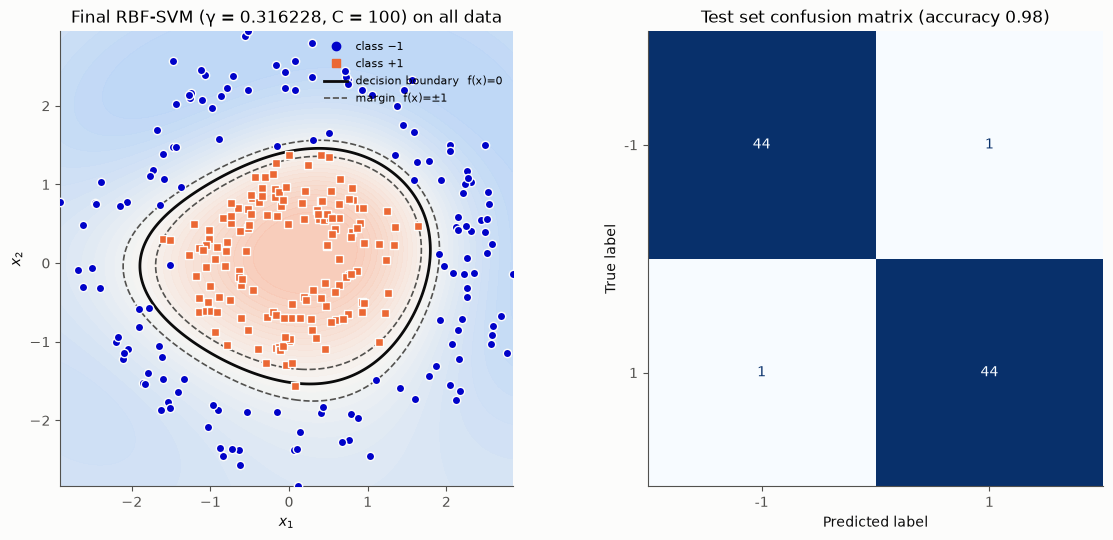

In [182]:
# Das Modell mit den besten Hyperparametern, von GridSearchCV auf dem gesamten Trainingsset neu trainiert
best = search.best_estimator_
# Zwei Plots: Entscheidungsbereiche (links) und Confusion Matrix auf dem Testset (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))
# Links: Entscheidungsbereiche des finalen Modells auf den Ringdaten; gamma und C stehen im Titel
plot_svm(ax1, best, X_nl, y_nl, f"Final RBF-SVM (γ = {best.gamma:g}, C = {best.C:g}) on all data", show_sv=False)
ax1.legend(handles=legend_handles(False), loc="upper right", fontsize=8)
ax1.set_aspect("equal")
# Rechts: Confusion Matrix auf dem Testset (Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse)
ConfusionMatrixDisplay.from_estimator(best, Xn_te, yn_te, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title(f"Test set confusion matrix (accuracy {best.score(Xn_te, yn_te):.2f})"); ax2.grid(False)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()

---
# Summary

| | Linear SVM | RBF-kernel SVM |
|---|---|---|
| Decision function | $f(x) = w^\top x + b$ | $f(x) = \sum_i \alpha_i y_i \exp(-\gamma\lVert x_i - x\rVert^2) + b$ |
| Boundary in input space | hyperplane | arbitrary smooth curve / surface |
| Hyper-parameters | $C$ | $C$, $\gamma$ |
| Feature space | input space | infinite-dimensional (implicit) |

**Key take-aways**

1. An SVM chooses the separating hyperplane with the **maximum margin** $2/\lVert w\rVert$, found by minimising
   $\tfrac12\lVert w\rVert^2$ subject to $y_i(w^\top x_i+b)\ge 1$.
2. The **soft margin** (slack variables / hinge loss) handles noise and overlap; $C$ trades margin width
   against violations.
3. The **dual** shows that the solution $w = \sum_i\alpha_i y_i x_i$ depends only on the **support vectors**,
   and only through **inner products**.
4. The **kernel trick** replaces inner products with a kernel $K(x,z)=\phi(x)^\top\phi(z)$, giving a linear
   classifier in a (possibly infinite-dimensional) feature space without ever computing $\phi$.
5. The **RBF kernel** measures similarity by distance; $\gamma$ and $C$ control under- vs. over-fitting and are
   chosen by **cross-validation**.